# 01 · Data Preparation
**RedactNER: Local PII Redaction for Word Documents**

This notebook builds the training, development and test sets used to fine-tune and compare the PII
token classifiers. It runs in the project environment or on Google Colab.

| Role | Dataset | Content | Licence |
|---|---|---|---|
| Training, Development and Test | `nvidia/Nemotron-PII` | Document-style synthetic PII such as resumes, forms and reports | CC BY 4.0 |
| Training, Development and Test | `ai4privacy/pii-masking-openpii-1.5m` (English rows) | Short synthetic emails, forms and chat messages | CC BY 4.0 |
| Test Only | `gretelai/synthetic_pii_finance_multilingual` (English rows) | Long financial documents from a generator not used for training | Apache 2.0 |

Every source is mapped onto a single taxonomy of 13 categories: Person, Email, Phone, Address,
Location, Date, ID Number, Financial, Username, Credential, IP Address, URL and Organisation.
Character offsets are validated, span conventions are harmonised, and test documents that also appear
in the training pool are removed. The datasets are subsampled so that training fits on a single
consumer GPU.

In [1]:
N_NEMOTRON_TRAIN = 15000
N_NEMOTRON_DEV = 1000
N_NEMOTRON_TEST = 1000
N_AI4P_TRAIN = 10000
N_AI4P_DEV = 500
N_AI4P_TEST = 1000
N_GRETEL_TEST = 500
SEED = 42
PROJECT_DIR = ".."  # notebooks/ lives one level below the project root

## 0. Setup
On Google Colab this cell installs the additional packages required. Locally, all dependencies come
from the project environment created with `uv sync`.

In [2]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets>=3.0", "matplotlib", "pandas"], check=True)
    PROJECT_DIR = "/content/redactner"

import ast
import hashlib
import json
import random
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

ROOT = Path(PROJECT_DIR).resolve()
DATA_OUT = ROOT / "data" / "processed"
FIG_DIR = ROOT / "results" / "prototype"
DATA_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
rng = random.Random(SEED)

## 1. Taxonomy and Label Mappings
Source labels outside the taxonomy, such as job titles, gender, age, sensitive attributes and times,
are mapped to `None` and treated as non-PII (`O`).

In [3]:
LABELS = ["PERSON", "EMAIL", "PHONE", "ADDRESS", "LOCATION", "DATE", "ID_NUMBER", "FINANCIAL",
          "USERNAME", "CREDENTIAL", "IP_ADDRESS", "URL", "ORGANIZATION"]
BIO_LABELS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
CATEGORY_NAMES = {"PERSON": "Person", "EMAIL": "Email", "PHONE": "Phone", "ADDRESS": "Address",
                  "LOCATION": "Location", "DATE": "Date", "ID_NUMBER": "ID Number", "FINANCIAL": "Financial",
                  "USERNAME": "Username", "CREDENTIAL": "Credential", "IP_ADDRESS": "IP Address", "URL": "URL",
                  "ORGANIZATION": "Organisation"}
SPLIT_NAMES = {"train": "Training", "dev": "Development", "test_nemotron": "Nemotron-PII Test",
               "test_ai4privacy": "ai4privacy Test", "test_gretel": "Gretel Finance Test"}

NEMOTRON_MAP = {
    "first_name": "PERSON", "last_name": "PERSON", "name": "PERSON", "middle_name": "PERSON",
    "email": "EMAIL",
    "phone_number": "PHONE", "fax_number": "PHONE",
    "street_address": "ADDRESS", "postcode": "ADDRESS",
    "city": "LOCATION", "county": "LOCATION", "state": "LOCATION", "coordinate": "LOCATION",
    "date": "DATE", "date_of_birth": "DATE", "date_time": "DATE",
    "ssn": "ID_NUMBER", "national_id": "ID_NUMBER", "tax_id": "ID_NUMBER",
    "medical_record_number": "ID_NUMBER", "health_plan_beneficiary_number": "ID_NUMBER",
    "customer_id": "ID_NUMBER", "employee_id": "ID_NUMBER", "unique_id": "ID_NUMBER",
    "certificate_license_number": "ID_NUMBER", "license_plate": "ID_NUMBER",
    "vehicle_identifier": "ID_NUMBER", "device_identifier": "ID_NUMBER", "biometric_identifier": "ID_NUMBER",
    "account_number": "FINANCIAL", "bank_routing_number": "FINANCIAL", "swift_bic": "FINANCIAL",
    "credit_debit_card": "FINANCIAL",
    "cvv": "CREDENTIAL", "pin": "CREDENTIAL", "password": "CREDENTIAL", "api_key": "CREDENTIAL",
    "http_cookie": "CREDENTIAL",
    "ipv4": "IP_ADDRESS", "ipv6": "IP_ADDRESS", "mac_address": "IP_ADDRESS",
    "url": "URL",
    "user_name": "USERNAME",
    "company_name": "ORGANIZATION",
    # quasi-identifiers and sensitive attributes outside the taxonomy
    "age": None, "gender": None, "race_ethnicity": None, "sexuality": None, "religious_belief": None,
    "political_view": None, "marital_status": None, "nationality": None, "education_level": None,
    "occupation": None, "employment_status": None, "language": None, "blood_type": None,
    "country": None, "time": None,
}

AI4P_MAP = {
    "GIVENNAME": "PERSON", "SURNAME": "PERSON", "TITLE": None,
    "EMAIL": "EMAIL", "TELEPHONENUM": "PHONE",
    "STREET": "ADDRESS", "BUILDINGNUM": "ADDRESS", "ZIPCODE": "ADDRESS", "CITY": "LOCATION",
    "DATE": "DATE", "TIME": None, "AGE": None, "GENDER": None, "SEX": None,
    "IDCARDNUM": "ID_NUMBER", "PASSPORTNUM": "ID_NUMBER", "DRIVERLICENSENUM": "ID_NUMBER",
    "SOCIALNUM": "ID_NUMBER", "TAXNUM": "ID_NUMBER",
    "CREDITCARDNUMBER": "FINANCIAL", "USERNAME": "USERNAME", "BANKNAME": None,
}

GRETEL_MAP = {
    "name": "PERSON", "first_name": "PERSON", "last_name": "PERSON",
    "email": "EMAIL", "phone_number": "PHONE",
    "street_address": "ADDRESS", "local_latlng": "LOCATION",
    "date": "DATE", "date_of_birth": "DATE", "date_time": "DATE", "time": None,
    "company": "ORGANIZATION",
    "ssn": "ID_NUMBER", "driver_license_number": "ID_NUMBER", "passport_number": "ID_NUMBER",
    "customer_id": "ID_NUMBER", "employee_id": "ID_NUMBER",
    "account_pin": "CREDENTIAL", "password": "CREDENTIAL", "api_key": "CREDENTIAL",
    "credit_card_security_code": "CREDENTIAL",
    "bban": "FINANCIAL", "iban": "FINANCIAL", "swift_bic_code": "FINANCIAL",
    "bank_routing_number": "FINANCIAL", "credit_card_number": "FINANCIAL",
    "ipv4": "IP_ADDRESS", "ipv6": "IP_ADDRESS",
    "user_name": "USERNAME",
}

unknown_labels: Counter = Counter()


def map_label(mapping: dict, raw: str, source: str):
    if raw in mapping:
        return mapping[raw]
    key = raw.lower() if source != "ai4privacy" else raw.upper()
    if key in mapping:
        return mapping[key]
    unknown_labels[(source, raw)] += 1
    return None

## 2. Span Harmonisation
* Offsets are validated against the text and, where the source provides it, against the stored value.
* Leading and trailing whitespace, possessive *'s* and trailing punctuation are trimmed.
* Overlapping spans are resolved in favour of the longest span.
* Adjacent spans of the same category separated only by whitespace are merged, for example
  `first_name` and `last_name` into one Person span, or `BUILDINGNUM` and `STREET` into one Address span.

In [4]:
TRAIL_PUNCT = ",;:"
POSSESSIVE = re.compile(r"(?:'s|’s)$")


def clean_span(text: str, start: int, end: int, label: str):
    while start < end and text[start].isspace():
        start += 1
    while end > start and (text[end - 1].isspace() or text[end - 1] in TRAIL_PUNCT):
        end -= 1
    if label in ("EMAIL", "URL", "PERSON") and end > start and text[end - 1] == ".":
        end -= 1
    if label == "PERSON":
        m = POSSESSIVE.search(text[start:end])
        if m:
            end -= len(m.group(0))
    return (start, end) if end > start else None


def harmonise(text: str, raw_spans: list[tuple[int, int, str]]) -> list[list]:
    spans = []
    for s, e, lab in raw_spans:
        c = clean_span(text, s, e, lab)
        if c:
            spans.append((c[0], c[1], lab))
    # overlap resolution: longest first
    kept: list[tuple[int, int, str]] = []
    for s, e, lab in sorted(spans, key=lambda x: (-(x[1] - x[0]), x[0])):
        if all(e <= ks or s >= ke for ks, ke, _ in kept):
            kept.append((s, e, lab))
    kept.sort()
    # merge adjacent same-type spans separated by whitespace (ADDRESS also by a comma)
    merged: list[list] = []
    for s, e, lab in kept:
        if merged and merged[-1][2] == lab:
            gap = text[merged[-1][1]:s]
            if (gap.strip() == "" and len(gap) <= 2) or (lab == "ADDRESS" and gap.strip() == "," and len(gap) <= 3):
                merged[-1][1] = e
                continue
        merged.append([s, e, lab])
    return merged


def text_key(text: str) -> str:
    return hashlib.sha1(re.sub(r"\s+", " ", text.lower()).strip().encode()).hexdigest()

## 3. Load the Sources

In [5]:
t0 = time.time()
nemo = load_dataset("nvidia/Nemotron-PII")
print(nemo)
print("Features:", nemo["train"].features)

DatasetDict({
    train: Dataset({
        features: ['uid', 'domain', 'document_type', 'document_description', 'document_format', 'locale', 'text', 'spans', 'text_tagged'],
        num_rows: 100000
    })
    test: Dataset({
        features: ['uid', 'domain', 'document_type', 'document_description', 'document_format', 'locale', 'text', 'spans', 'text_tagged'],
        num_rows: 100000
    })
})
Features: {'uid': Value('string'), 'domain': Value('string'), 'document_type': Value('string'), 'document_description': Value('string'), 'document_format': Value('string'), 'locale': Value('string'), 'text': Value('string'), 'spans': Value('string'), 'text_tagged': Value('string')}


In [6]:
def parse_spans(value):
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return ast.literal_eval(value)
    return value or []


def nemotron_record(row, idx, split):
    text = row["text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["spans"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)):
            bad += 1
            continue
        if sp.get("text") is not None and text[s:e] != sp["text"]:
            bad += 1
            continue
        lab = map_label(NEMOTRON_MAP, sp["label"], "nemotron")
        if lab:
            raw.append((s, e, lab))
    return {
        "id": f"nemotron-{split}-{row.get('uid', idx)}",
        "source": "nemotron",
        "text": text,
        "spans": harmonise(text, raw),
        "meta": {"document_type": row.get("document_type"), "format": row.get("document_format"),
                 "locale": row.get("locale"), "domain": row.get("domain")},
        "_bad_spans": bad,
    }


train_keys = {text_key(t) for t in nemo["train"]["text"]}
print(f"Unique training texts: {len(train_keys):,} of {len(nemo['train']):,}")

nemo_train_idx = list(range(len(nemo["train"])))
rng.shuffle(nemo_train_idx)
nemo_train_idx = nemo_train_idx[: N_NEMOTRON_TRAIN + N_NEMOTRON_DEV]

test_idx = [i for i, t in enumerate(nemo["test"]["text"]) if text_key(t) not in train_keys]
print(f"Nemotron-PII test documents not present in training: {len(test_idx):,} of {len(nemo['test']):,}")
rng.shuffle(test_idx)
test_idx = test_idx[:N_NEMOTRON_TEST]

nemo_pool = [nemotron_record(nemo["train"][i], i, "train") for i in nemo_train_idx]
nemo_test = [nemotron_record(nemo["test"][i], i, "test") for i in test_idx]
nemo_train, nemo_dev = nemo_pool[:N_NEMOTRON_TRAIN], nemo_pool[N_NEMOTRON_TRAIN:]
print(f"Nemotron-PII: {len(nemo_train):,} training | {len(nemo_dev):,} development | {len(nemo_test):,} test | "
      f"{sum(r['_bad_spans'] for r in nemo_pool + nemo_test):,} invalid spans removed ({time.time() - t0:.0f} s)")

Unique training texts: 99,999 of 100,000


Nemotron-PII test documents not present in training: 100,000 of 100,000


Nemotron-PII: 15,000 training | 1,000 development | 1,000 test | 2,131 invalid spans removed (13 s)


The full OpenPII-1.5M corpus is streamed and the first English rows are kept. English accounts for
roughly 12 % of the corpus, so only a few shards need to be read. The stratified `micro-100k` sample is
used only as a fallback because it contains too few English rows.

In [7]:
PLACEHOLDER = re.compile(r"[A-Z]+PLACEHOLDER")


def ai4p_english(split: str, n: int):
    rows = []
    for repo in ("ai4privacy/pii-masking-openpii-1.5m", "ai4privacy/pii-masking-micro-100k"):
        try:
            ds = load_dataset(repo, split=split, streaming=True)
        except Exception as exc:  # noqa: BLE001 - fall back to the next repository
            print(f"  {repo} ({split}): unavailable ({type(exc).__name__}), trying the next source")
            continue
        for row in ds:
            lang = str(row.get("language", "")).lower()
            if not lang.startswith("en"):
                continue
            if PLACEHOLDER.search(row["source_text"]):
                continue
            rows.append(row)
            if len(rows) >= n:
                break
        print(f"  {repo} ({split}): {len(rows):,} English rows")
        if len(rows) >= 0.9 * n:
            return rows
        rows = []
    raise RuntimeError("No ai4privacy source is available")


def ai4p_record(row, idx, split):
    text = row["source_text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["privacy_mask"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)) or (sp.get("value") is not None and text[s:e] != sp["value"]):
            bad += 1
            continue
        lab = map_label(AI4P_MAP, sp["label"], "ai4privacy")
        if lab:
            raw.append((s, e, lab))
    return {"id": f"ai4privacy-{split}-{row.get('uid', idx)}", "source": "ai4privacy", "text": text,
            "spans": harmonise(text, raw), "meta": {"region": row.get("region") or row.get("locale")},
            "_bad_spans": bad}


t0 = time.time()
ai4p_rows = ai4p_english("train", N_AI4P_TRAIN + N_AI4P_DEV)
rng.shuffle(ai4p_rows)
ai4p_pool = [ai4p_record(r, i, "train") for i, r in enumerate(ai4p_rows)]
ai4p_train, ai4p_dev = ai4p_pool[:N_AI4P_TRAIN], ai4p_pool[N_AI4P_TRAIN:N_AI4P_TRAIN + N_AI4P_DEV]
ai4p_test_rows = ai4p_english("validation", N_AI4P_TEST)
ai4p_train_keys = {text_key(r["text"]) for r in ai4p_pool}
ai4p_test = [r for r in (ai4p_record(x, i, "validation") for i, x in enumerate(ai4p_test_rows))
             if text_key(r["text"]) not in ai4p_train_keys]
print(f"ai4privacy OpenPII: {len(ai4p_train):,} training | {len(ai4p_dev):,} development | {len(ai4p_test):,} test | "
      f"{sum(r['_bad_spans'] for r in ai4p_pool + ai4p_test):,} invalid spans removed ({time.time() - t0:.0f} s)")

  ai4privacy/pii-masking-openpii-1.5m (train): 10,500 English rows


  ai4privacy/pii-masking-openpii-1.5m (validation): 1,000 English rows
ai4privacy OpenPII: 10,000 training | 500 development | 999 test | 0 invalid spans removed (79 s)


In [8]:
t0 = time.time()
gretel = load_dataset("gretelai/synthetic_pii_finance_multilingual", split="test")
gretel_en = [i for i, lang in enumerate(gretel["language"]) if str(lang).lower().startswith("english")]
rng.shuffle(gretel_en)


def gretel_record(row, idx):
    text = row["generated_text"]
    raw = []
    bad = 0
    for sp in parse_spans(row["pii_spans"]):
        s, e = int(sp["start"]), int(sp["end"])
        if not (0 <= s < e <= len(text)):
            bad += 1
            continue
        lab = map_label(GRETEL_MAP, sp["label"], "gretel")
        if lab:
            raw.append((s, e, lab))
    return {"id": f"gretel-test-{idx}", "source": "gretel", "text": text, "spans": harmonise(text, raw),
            "meta": {"document_type": row.get("document_type")}, "_bad_spans": bad}


gretel_test = [gretel_record(gretel[i], i) for i in gretel_en[:N_GRETEL_TEST]]
print(f"Gretel Finance: {len(gretel_test):,} English test documents ({time.time() - t0:.0f} s)")
print("Unmapped source labels:", dict(unknown_labels.most_common(20)) or "none")

Gretel Finance: 500 English test documents (3 s)
Unmapped source labels: {('ai4privacy', 'AMOUNT'): 14, ('ai4privacy', 'CURRENCY'): 11, ('ai4privacy', 'ORGANISATION'): 7, ('ai4privacy', 'COUNTRY'): 5, ('ai4privacy', 'URL'): 3, ('ai4privacy', 'SALARY'): 1}


## 4. Write the Processed Splits
The training and development sets are shuffled mixtures of both training sources. The test sets are kept
separate so that results can be reported for each domain.

In [9]:
def dump(name: str, records: list[dict]) -> None:
    with open(DATA_OUT / f"{name}.jsonl", "w", encoding="utf-8") as fh:
        for r in records:
            r = {k: v for k, v in r.items() if not k.startswith("_")}
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")


train = nemo_train + ai4p_train
dev = nemo_dev + ai4p_dev
rng.shuffle(train)
rng.shuffle(dev)
splits = {"train": train, "dev": dev, "test_nemotron": nemo_test, "test_ai4privacy": ai4p_test,
          "test_gretel": gretel_test}
for name, recs in splits.items():
    dump(name, recs)

with open(DATA_OUT / "labels.json", "w", encoding="utf-8") as fh:
    json.dump({"labels": LABELS, "bio_labels": BIO_LABELS,
               "mappings": {"nemotron": NEMOTRON_MAP, "ai4privacy": AI4P_MAP, "gretel": GRETEL_MAP}}, fh, indent=2)
print("Splits written to", DATA_OUT.relative_to(ROOT).as_posix())

Splits written to data/processed


## 5. Exploratory Statistics

In [10]:
rows = []
for name, recs in splits.items():
    n_chars = sum(len(r["text"]) for r in recs)
    pii_chars = sum(e - s for r in recs for s, e, _ in r["spans"])
    rows.append({"Split": SPLIT_NAMES[name], "Documents": len(recs), "Entities": sum(len(r["spans"]) for r in recs),
                 "Mean Characters": round(n_chars / max(len(recs), 1)),
                 "PII Characters (%)": round(100 * pii_chars / max(n_chars, 1), 2),
                 "Documents Without PII (%)": round(100 * sum(not r["spans"] for r in recs) / max(len(recs), 1), 1)})
stats_df = pd.DataFrame(rows).set_index("Split")
stats_df

,Documents,Entities,Mean Characters,PII Characters (%),Documents Without PII (%)
Split,,,,,
Training,25000,151832,749,13.45,0.5
Development,1500,8988,770,12.95,0.3
Nemotron-PII Test,1000,6414,949,11.33,0.0
ai4privacy Test,999,5403,369,22.34,0.7
Gretel Finance Test,500,2971,1380,7.29,8.6


In [11]:
counts = defaultdict(Counter)
for name, recs in splits.items():
    for r in recs:
        for _, _, lab in r["spans"]:
            counts[SPLIT_NAMES[name]][lab] += 1
label_df = pd.DataFrame(counts).reindex(LABELS).fillna(0).astype(int).rename(index=CATEGORY_NAMES)
label_df.index.name = "Category"
label_df

,Training,Development,Nemotron-PII Test,ai4privacy Test,Gretel Finance Test
Category,,,,,
Person,20485,1169,937,1000,671
Email,13094,751,564,553,116
Phone,8848,539,327,434,90
Address,10941,636,214,756,387
Location,13075,728,514,517,14
Date,24922,1405,1084,902,919
ID Number,24626,1481,874,985,73
Financial,7491,435,404,256,97
Username,1875,154,171,0,6


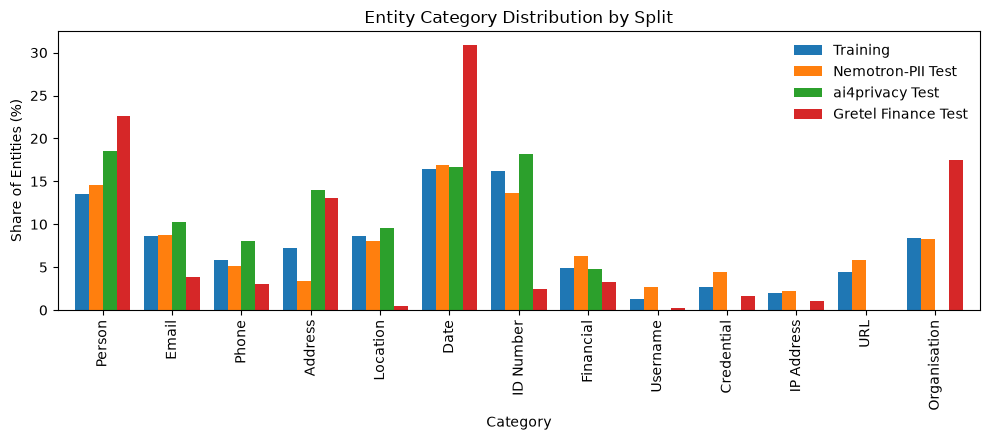

In [12]:
plot_cols = [SPLIT_NAMES[k] for k in ("train", "test_nemotron", "test_ai4privacy", "test_gretel")]
fig, ax = plt.subplots(figsize=(10, 4.5))
(label_df[plot_cols].div(label_df[plot_cols].sum(), axis=1) * 100).plot.bar(ax=ax, width=0.8)
ax.set_xlabel("Category")
ax.set_ylabel("Share of Entities (%)")
ax.set_title("Entity Category Distribution by Split")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_label_distribution.png", dpi=150)
plt.show()

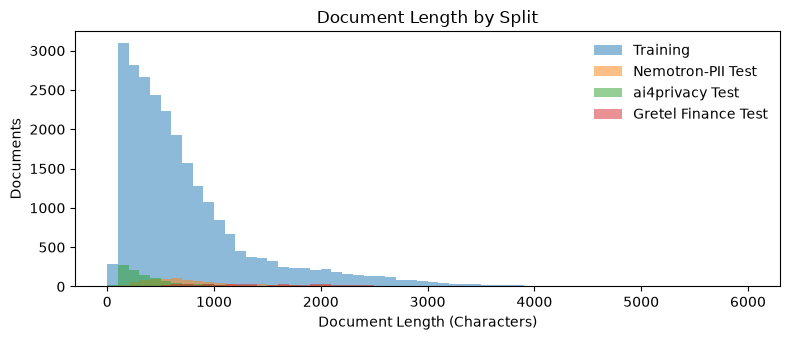

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ("train", "test_nemotron", "test_ai4privacy", "test_gretel"):
    ax.hist([len(r["text"]) for r in splits[name]], bins=60, alpha=0.5, label=SPLIT_NAMES[name], range=(0, 6000))
ax.set_xlabel("Document Length (Characters)")
ax.set_ylabel("Documents")
ax.legend(frameon=False)
ax.set_title("Document Length by Split")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_doc_lengths.png", dpi=150)
plt.show()

with open(FIG_DIR / "data_stats.json", "w", encoding="utf-8") as fh:
    json.dump({"splits": stats_df.reset_index().to_dict(orient="records"),
               "entities_per_category": label_df.to_dict()}, fh, indent=2)

The example below shows harmonised training documents with their entities marked inline.

In [14]:
def show(rec, width=700):
    out, last = [], 0
    for s, e, lab in rec["spans"]:
        out.append(rec["text"][last:s])
        out.append(f"[{rec['text'][s:e]}|{lab}]")
        last = e
    out.append(rec["text"][last:])
    print("".join(out)[:width])


show(next(r for r in train if r["source"] == "nemotron" and len(r["spans"]) > 4))
print()
show(next(r for r in train if r["source"] == "ai4privacy" and len(r["spans"]) > 2))

**Telecommunications Call Blocking Request**

**Customer Account Information**

Customer ID: [SM-73254|ID_NUMBER]
Phone Number: [559-584-7805|PHONE]

**Call Blocking Details**

Request Date: [2028-09-15|DATE]
Reason for Blocking: Unwanted Calls

**Service Provider Details**

Service Provider: [To be filled by the service provider]

**Additional Information**

Please block the phone number [559-584-7805|PHONE] from all incoming calls. This request is made by the customer with customer id [SM-73254|ID_NUMBER] on the date [2028-09-15|DATE].

Dear Madame [Karole Sbigottiti|PERSON], we have accelerated the liability payment for your account (ID: [S6RCWQ145I|ID_NUMBER]) to settle the invoice dated [2017-11-08T00:00:00|DATE] with a new due date of [14/03/1977|DATE].
